In [ ]:
import pandas as pd
import statsmodels.graphics.tsaplots as tsa_plots
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error
from matplotlib import pyplot as plt

In [ ]:
Walmart=pd.read_csv("/content/Walmart Footfalls Raw.csv")
train=Walmart.head(147)
test=Walmart.tail(12)
print("=====Stationarity check(ADF test)====")
result=adfuller(train.Footfalls)
print("ADF Static:",result[0])
print("p-value:",result[1])

=====Stationarity check(ADF test)====
ADF Static: -0.8725058977579946
p-value: 0.7968917502773996


In [ ]:
diff1=train.Footfalls.diff().dropna()
result1=adfuller(diff1)
print("\nafter 1st diference p-value:",result1[1])


after 1st diference p-value: 0.017033761455931197


In [ ]:
diff2=diff1.diff().dropna()
result2=adfuller(diff2)
print("after 2nd difference p-alue:",result2[1])

after 2nd difference p-alue: 1.2438549674329634e-18


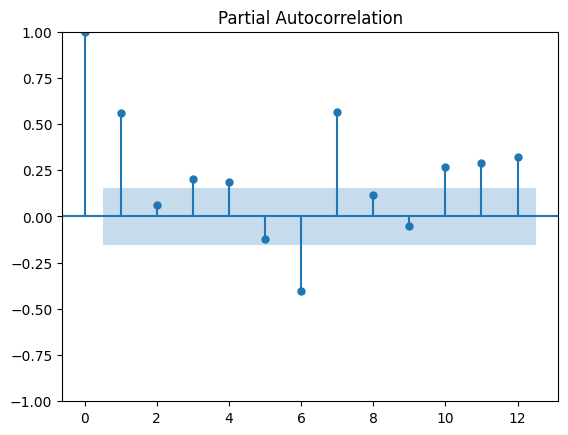

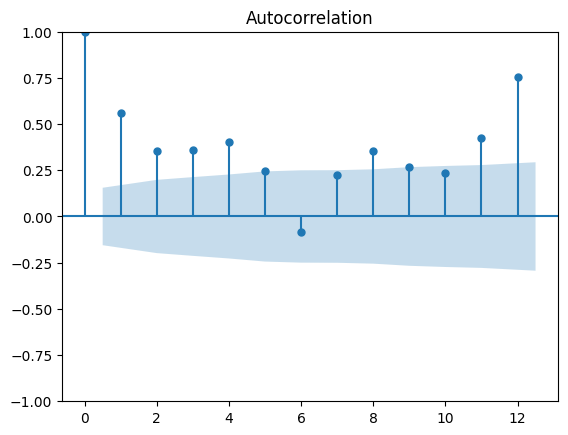

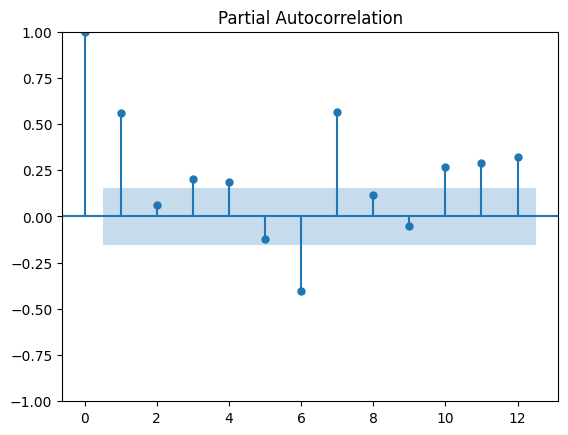

In [ ]:
tsa_plots.plot_acf(Walmart.Footfalls,lags=12)
tsa_plots.plot_pacf(Walmart.Footfalls,lags=12)

In [ ]:
model1=ARIMA(train.Footfalls,order=(2,1,2))
model1_fit=model1.fit()
print(model1_fit.summary)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


<bound method SARIMAXResults.summary of <statsmodels.tsa.arima.model.ARIMAResults object at 0x7db7bdfe9be0>>


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [ ]:
start_index=len(train)
end_index=start_index+len(test)-1
forecast_test=model1_fit.predict(start=start_index,end=end_index)
print("\nforecasted values:",forecast_test)


forecasted values: 147    2028.462184
148    1840.622433
149    1879.070342
150    2065.356208
151    2026.014273
152    1841.277004
153    1881.497045
154    2064.691066
155    2023.608696
156    1841.952511
157    1883.881578
158    2064.005398
Name: predicted_mean, dtype: float64


In [ ]:
import numpy as np
rmse_test=np.sqrt(mean_squared_error(test.Footfalls,forecast_test))
print("\ntest RMSE:%.3f" % rmse_test)


test RMSE:150.204


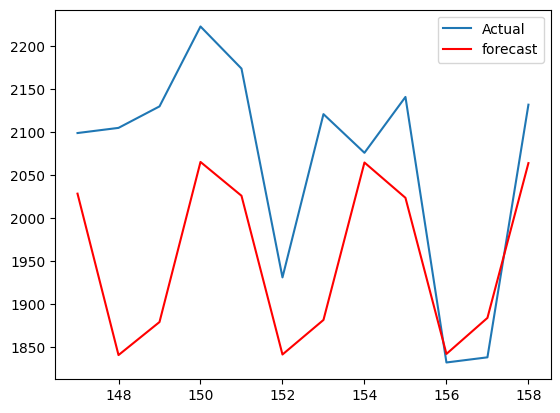

In [ ]:
plt.plot(test.Footfalls,label="Actual")
plt.plot(forecast_test,color='red',label="forecast")
plt.legend()
plt.show()

In [ ]:
import pandas as pd
import statsmodels.graphics.tsaplots as tsa_plots
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
from math import sqrt
from matplotlib import pyplot as plt

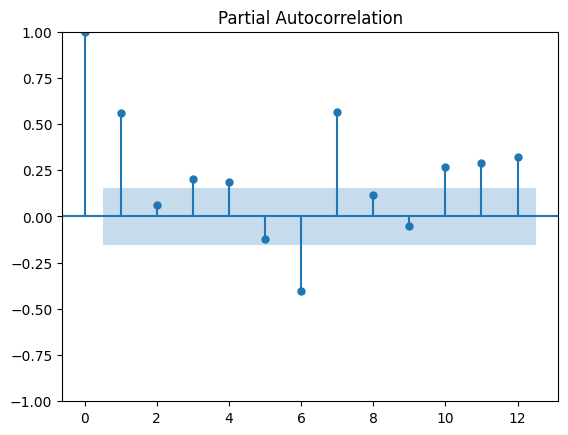

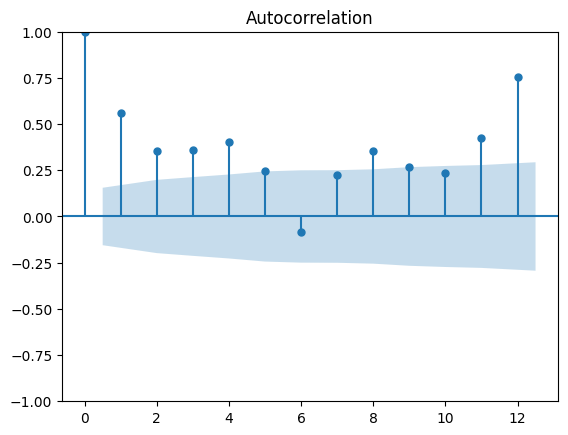

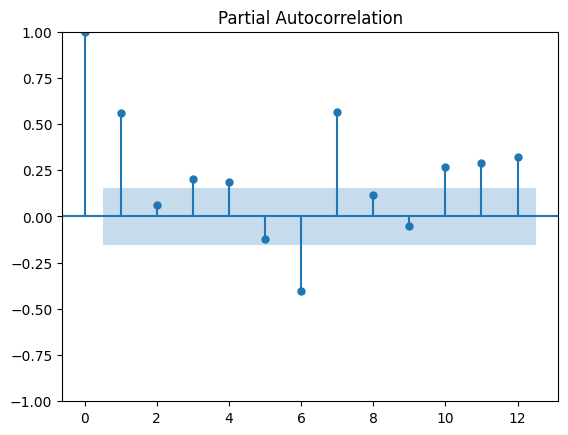

In [ ]:
Walmart=pd.read_csv("/content/Walmart Footfalls Raw.csv")
train=Walmart.head(147)
test=Walmart.tail(12)
tsa_plots.plot_acf(Walmart.Footfalls,lags=12)
tsa_plots.plot_pacf(Walmart.Footfalls,lags=12)

In [ ]:
model1=ARIMA(train.Footfalls,order=(4,1,6))
res1=model1.fit()
print(res1.summary())

                               SARIMAX Results                                
Dep. Variable:              Footfalls   No. Observations:                  147
Model:                 ARIMA(4, 1, 6)   Log Likelihood                -895.550
Date:                Thu, 25 Jun 2026   AIC                           1813.099
Time:                        10:33:39   BIC                           1845.919
Sample:                             0   HQIC                          1826.435
                                - 147                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7271      0.556     -1.307      0.191      -1.817       0.363
ar.L2         -0.7654      0.370     -2.067      0.039      -1.491      -0.040
ar.L3         -0.7165      0.560     -1.280      0.2

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [ ]:
start_index=len(train)
end_index-start_index+11
forecast_test=res1.predict(start=start_index,end=end_index)
print(forecast_test)

147    1921.131530
148    1870.834050
149    1860.602732
150    2022.684524
151    1978.296914
152    1836.477662
153    1855.009541
154    2020.255958
155    1977.030750
156    1835.130146
157    1857.374109
158    2019.900313
Name: predicted_mean, dtype: float64


In [ ]:
rmse_test=sqrt(mean_squared_error(test.Footfalls,forecast_test))
print("test RMSE:%.3f"%rmse_test)

test RMSE:173.230


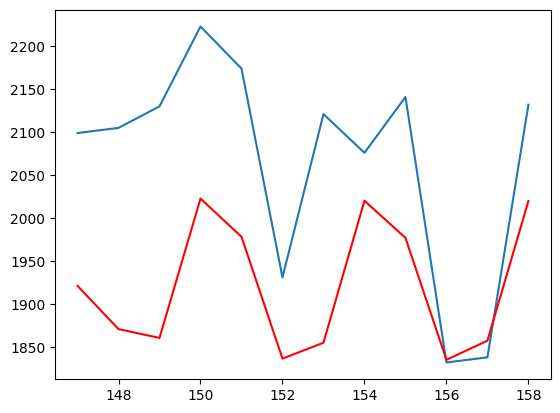

In [ ]:
plt.plot(test.Footfalls)
plt.plot(forecast_test,color='red')
plt.show()

In [ ]:
'''pmdarima is an Auto-ARIMA package that automatically selects the best (p,d,q) parameters for ARIMA.
start_p=0, start_q=0: Initial values for AR and MA terms.
max_p=12, max_q=12: Maximum values for AR and MA.
m=1: Indicates a non-seasonal model.
d=None: Automatically determines the differencing order.
seasonal=False: Disables seasonal components.
trace=True: Displays the selection process.
stepwise=True: Uses a stepwise approach for efficiency.'''

'pmdarima is an Auto-ARIMA package that automatically selects the best (p,d,q) parameters for ARIMA.\nstart_p=0, start_q=0: Initial values for AR and MA terms.\nmax_p=12, max_q=12: Maximum values for AR and MA.\nm=1: Indicates a non-seasonal model.\nd=None: Automatically determines the differencing order.\nseasonal=False: Disables seasonal components.\ntrace=True: Displays the selection process.\nstepwise=True: Uses a stepwise approach for efficiency.'

In [ ]:
!pip install pmdarima
import pmdarima as pm
ar_model=pm.auto_arima(train.Footfalls,start_p=0,start_q=0,
                       max_p=12,max_q=12,
                       m=1,
                       d=None,
                       seasonal=False,
                       trace=True,
                       error_action='warn',stepwise=True)
model=ARIMA(train.Footfalls,order=(3,1,5))
res=model.fit()
print(res.summary())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 19.0 MB/s eta 0:00:00
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1916.696, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1908.134, Time=0.03 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1887.358, Time=0.09 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1914.726, Time=0.02 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=1874.405, Time=0.32 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=1875.051, Time=0.49 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=1874.985, Time=0.53 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=1873.101, Time=0.87 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=1874.951, Time=0.58 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=1869.771, Time=0.26 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.47 sec
 ARIMA(1,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=0.38 sec
 ARIMA(0,1,4)(0,0,0)[0] intercept   : AIC=1859.122, Time=0.29 sec
 ARIMA(0,1,5)(0,0,0)[0] inte

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:              Footfalls   No. Observations:                  147
Model:                 ARIMA(3, 1, 5)   Log Likelihood                -894.721
Date:                Thu, 25 Jun 2026   AIC                           1807.442
Time:                        10:34:01   BIC                           1834.295
Sample:                             0   HQIC                          1818.353
                                - 147                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4693      0.257      1.828      0.068      -0.034       0.973
ar.L2         -0.9945      0.011    -92.910      0.000      -1.016      -0.974
ar.L3          0.4734      0.259      1.831      0.0

In [ ]:
start_index=len(train)
end_index=start_index+11
forecast_test=res.predict(start=start_index,end=end_index)
print(forecast_test)

147    1948.188666
148    1860.084237
149    1856.317837
150    1996.579889
151    1965.216070
152    1809.217208
153    1833.587581
154    1985.326164
155    1958.462537
156    1806.480453
157    1833.692831
158    1984.900584
Name: predicted_mean, dtype: float64


test RMSE:185.691


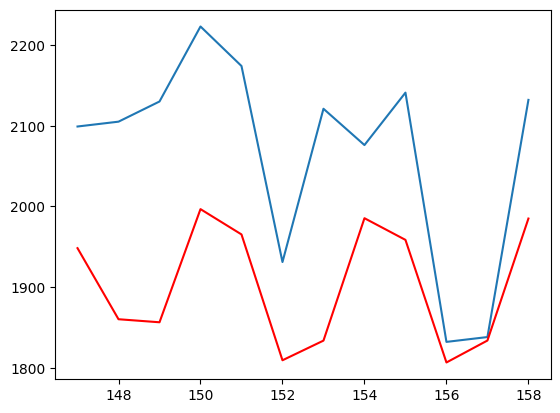

159    1976.145275
160    1834.032921
161    1859.664210
162    2019.625276
163    1975.168991
164    1833.052640
165    1861.863402
166    2019.410978
167    1974.112835
168    1832.176764
169    1863.982774
170    2019.246414
Name: predicted_mean, dtype: float64


In [ ]:
rmse_test=sqrt(mean_squared_error(test.Footfalls,forecast_test))
print("test RMSE:%.3f"%rmse_test)

plt.plot(test.Footfalls)
plt.plot(forecast_test,color='red')
plt.show()

start_index=len(Walmart)
end_index=start_index+11
forecast_test=res1.predict(start=start_index,end=end_index)
print(forecast_test)